# Task 2 — Notebook 1: ML Baselines
**Project:** Motor-Imagery EEG Classification Using Graph Neural Networks with Functional Channel Connectivity
**Dataset:** BCI Competition IV — dataset 2a (9 subjects, 22 EEG channels, 250 Hz, 4 motor-imagery classes)

This notebook continues from the Task 1 EDA notebook. It builds the classical baselines the GNN (Notebook 2) has to beat.

| Step | What happens | Leakage guard |
|---|---|---|
| 1 | Load the Task 1 export, drop EOG channels, band-pass filter | filtering is done trial by trial |
| 2 | **Subject-independent split** (train A01–A06, validation A07, test A08–A09) | no subject on two sides |
| 3 | Features: Task 1 features + log band power + Hjorth, per channel | computed inside each trial only |
| 4 | Imputation → scaling → feature selection → model, in one `Pipeline` | every step is fitted on train subjects only |
| 5 | Nine baselines, tuned on the validation subject, tested once | test subjects never used for any choice |
| 6 | Full metric set, confusion matrices, ROC / PR curves, timing, comparison table | — |
| 7 | Leave-one-subject-out check | — |

**What to expect form this task.** The task is 4-class, so chance is **25 % accuracy**. Scores of 70–80 % reported for this dataset are *within-subject* (train and test on the same person). Here the test people are never seen in training, which is much harder; 30–50 % is a normal range. A lower but honest number is the point of the subject-wise split.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Setup

In [2]:
import os, json, time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc, roc_auc_score,
    precision_recall_curve, average_precision_score, f1_score, recall_score,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except Exception:
    HAS_LGBM = False
print("XGBoost available:", HAS_XGB, "| LightGBM available:", HAS_LGBM)

XGBoost available: True | LightGBM available: True


In [3]:
from google.colab import drive
drive.mount("/content/drive")

# Same folder as Task 1
DATA_DIR = "/content/drive/MyDrive/475_mini_proj"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
PROCESSED_DIR = os.path.join(DATA_DIR, "Processed_Data")   # written by Task 1
RESULTS_DIR   = os.path.join(DATA_DIR, "Task2_Results")    # written by Task 2
FIG_DIR       = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def finish(fig, fname):
    """Save a figure to Drive and show it."""
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, fname), dpi=150, bbox_inches="tight")
    plt.show()

Evaluation helpers, It is shared with Notebook 2 so both notebooks compute every metric the same way.

In [5]:
METRIC_COLS = ["Accuracy", "Balanced acc", "Precision (macro)", "Recall (macro)", "F1 (macro)",
               "Precision (weighted)", "Recall (weighted)", "F1 (weighted)", "ROC-AUC (macro OvR)", "PR-AUC (macro OvR)"]

def compute_metrics(y_true, proba):
    y_pred = proba.argmax(1)
    Yb = label_binarize(y_true, classes=np.arange(N_CLASSES))
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, y_pred), "Balanced acc": balanced_accuracy_score(y_true, y_pred),
        "Precision (macro)": pm, "Recall (macro)": rm, "F1 (macro)": fm,
        "Precision (weighted)": pw, "Recall (weighted)": rw, "F1 (weighted)": fw,
        "ROC-AUC (macro OvR)": roc_auc_score(Yb, proba, average="macro"),
        "PR-AUC (macro OvR)": average_precision_score(Yb, proba, average="macro"),
    }

def per_class_table(y_true, proba):
    y_pred = proba.argmax(1)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(N_CLASSES), zero_division=0)
    Yb = label_binarize(y_true, classes=np.arange(N_CLASSES))
    rows = [{"class": CLASS_NAMES[c], "precision": p[c], "recall": r[c], "f1-score": f[c],
             "ROC-AUC": roc_auc_score(Yb[:, c], proba[:, c]), "support": int(s[c])} for c in range(N_CLASSES)]
    for avg in ["macro", "weighted"]:
        pa, ra, fa, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        rows.append({"class": f"{avg} avg", "precision": pa, "recall": ra, "f1-score": fa,
                     "ROC-AUC": roc_auc_score(Yb, proba, average=avg), "support": int(s.sum())})
    return pd.DataFrame(rows).set_index("class")

def plot_confusion(ax, y_true, y_pred, title, ylabel=True):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=8); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("Predicted class"); ax.set_title(title, fontsize=10)
    if ylabel:
        ax.set_ylabel("True class")
    else:
        ax.set_yticklabels([])
    return im

def read_confusion(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES)).astype(float)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    rec = np.diag(cmn); off = cmn.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"Reading ({name}): best-recognised class = {CLASS_NAMES[rec.argmax()]} (recall {rec.max():.2f}); "
          f"weakest = {CLASS_NAMES[rec.argmin()]} (recall {rec.min():.2f}); "
          f"most common mistake = true '{CLASS_NAMES[i]}' predicted as '{CLASS_NAMES[j]}' ({off[i, j]:.0%} of those trials).")

def plot_ovr_curves(y_true, proba, model_name, fname):
    """One-vs-rest ROC and precision-recall curves for one model."""
    Yb = label_binarize(y_true, classes=np.arange(N_CLASSES))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    aucs, aps = [], []
    for c, cname in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(Yb[:, c], proba[:, c]); aucs.append(auc(fpr, tpr))
        axes[0].plot(fpr, tpr, lw=2, label=f"{cname} (AUC = {aucs[-1]:.2f})")
        pr, rc, _ = precision_recall_curve(Yb[:, c], proba[:, c]); aps.append(average_precision_score(Yb[:, c], proba[:, c]))
        axes[1].plot(rc, pr, lw=2, label=f"{cname} (AP = {aps[-1]:.2f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.50)")
    axes[0].set(title=f"{model_name}: one-vs-rest ROC curves (test subjects)", xlabel="False positive rate", ylabel="True positive rate")
    prev = Yb.mean()
    axes[1].axhline(prev, color="k", ls="--", lw=1, label=f"Chance (AP = {prev:.2f})")
    axes[1].set(title=f"{model_name}: one-vs-rest precision-recall curves (test subjects)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
    axes[0].legend(loc="lower right"); axes[1].legend(loc="upper right")
    finish(fig, fname)
    print(f"Reading ({model_name}): every curve above the dashed line means the model ranks that class better than chance. "
          f"Easiest class to separate = {CLASS_NAMES[int(np.argmax(aucs))]} (AUC {max(aucs):.2f}, AP {aps[int(np.argmax(aucs))]:.2f}); "
          f"hardest = {CLASS_NAMES[int(np.argmin(aucs))]} (AUC {min(aucs):.2f}, AP {aps[int(np.argmin(aucs))]:.2f}). "
          f"Macro AUC = {np.mean(aucs):.3f}; chance is 0.50 for AUC and {prev:.2f} for AP.")

## 2. Load the Task 1 data
Task 1 saved `eeg_epochs.npz`, `eeg_metadata.csv` and `eeg_config.json` in `Processed_Data`. We reuse them so both tasks work on exactly the same **2,592 trials**. If the files are missing, the cell rebuilds the epochs from the `A0xT.gdf` files.

In [6]:
CLASS_CODES = {"Left hand": 769, "Right hand": 770, "Both feet": 771, "Tongue": 772}

def load_from_gdf(data_dir):
    """Fallback: rebuild the Task 1 epochs straight from the A0xT.gdf files."""
    import re, subprocess, sys
    try:
        import mne
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mne"], check=True)
        import mne
    paths = sorted(
        os.path.join(r, f) for r, _, fs in os.walk(data_dir) for f in fs
        if re.search(r"^A\d{2}T\.gdf$", f, re.I)
    )
    assert paths, "No A0xT.gdf files found under DATA_DIR."
    Xs, ys, subs, chs, sf = [], [], [], None, None
    for p in paths:
        raw = mne.io.read_raw_gdf(p, preload=True, verbose="ERROR")
        events, ann = mne.events_from_annotations(raw, verbose="ERROR")
        c2e = {int(d): e for d, e in ann.items() if str(d).isdigit()}
        ev_id = {lab: c2e[c] for lab, c in CLASS_CODES.items()}
        ep = mne.Epochs(raw, events, event_id=ev_id, tmin=0.0, tmax=3.996, baseline=None,
                        preload=True, verbose="ERROR")
        inv = {v: k for k, v in ev_id.items()}
        Xs.append(ep.get_data(units="uV").astype(np.float32))
        ys.append(np.array([inv[c] for c in ep.events[:, 2]]))
        subs.append(np.array([os.path.basename(p)[:3]] * len(ep)))
        chs, sf = ep.ch_names, ep.info["sfreq"]
        print(os.path.basename(p), Xs[-1].shape)
    return np.concatenate(Xs), np.concatenate(ys), np.concatenate(subs), list(chs), float(sf)

npz_path = os.path.join(PROCESSED_DIR, "eeg_epochs.npz")
if os.path.exists(npz_path):
    d = np.load(npz_path)
    X_raw, y_names = d["X"], d["y"].astype(str)
    subjects = pd.read_csv(os.path.join(PROCESSED_DIR, "eeg_metadata.csv"))["subject"].astype(str).values
    cfg = json.load(open(os.path.join(PROCESSED_DIR, "eeg_config.json")))
    channel_names, sfreq = cfg["channel_names"], float(cfg["sampling_frequency"])
    print("Loaded the Task 1 export from", PROCESSED_DIR)
else:
    print("Task 1 export not found -> re-reading the GDF files (takes a few minutes).")
    X_raw, y_names, subjects, channel_names, sfreq = load_from_gdf(DATA_DIR)

assert len(X_raw) == len(y_names) == len(subjects)
print("Epochs:", X_raw.shape, "| sampling rate:", sfreq, "Hz | subjects:", sorted(set(subjects)))

Loaded the Task 1 export from /content/drive/MyDrive/475_mini_proj/Processed_Data
Epochs: (2592, 25, 1000) | sampling rate: 250.0 Hz | subjects: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']


## 3. Preprocessing

**We find "A correction" to Task 1.** The Task 1 tensor has **25** channels: the **three EOG** (eye-movement) channels were kept, because MNE labels every channel in these GDF files as "EEG". EOG channels are **not brain** signals, and **eye movements** can correlate with the cue, so a model could score **well for the wrong reason**. They **are removed here**, leaving the 22 real EEG channels, which are renamed to their standard 10–20 names (the official order of the dataset 2a).

**Filtering.** Task 1 epochs are **unfiltered**. A 4–40 Hz band-pass removes **slow drift** and mains noise and keeps the mu (8–13 Hz) and beta (13–30 Hz) rhythms that motor imagery changes. Each trial is **filtered on its own**, so nothing passes between trials or subjects. The first 0.5 s after the cue is dropped (reaction time and the visual response to the cue).

In [7]:
# --- 1. keep the 22 EEG channels, drop the 3 EOG channels -------------------
STD_22 = ["Fz", "FC3", "FC1", "FCz", "FC2", "FC4", "C5", "C3", "C1", "Cz", "C2", "C4", "C6",
          "CP3", "CP1", "CPz", "CP2", "CP4", "P1", "Pz", "P2", "POz"]   # official 2a montage order
eeg_idx = [i for i, ch in enumerate(channel_names) if "EOG" not in ch.upper()]
assert len(eeg_idx) == 22, f"Expected 22 EEG channels, found {len(eeg_idx)}"
ch_names = STD_22
N_CH = 22

# --- 2. data-quality check (Task 1 found no NaN/Inf; we re-check) -----------
n_bad = int((~np.isfinite(X_raw)).sum())
print("Non-finite samples:", n_bad)
if n_bad:
    X_raw = np.nan_to_num(X_raw, nan=0.0, posinf=0.0, neginf=0.0)

# --- 3. band-pass 4-40 Hz, one trial at a time, then keep 0.5-4.0 s after the cue
def bandpass(X, lo, hi, fs, order=4):
    sos = butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, X, axis=-1).astype(np.float32)

T0, T1 = int(0.5 * sfreq), int(4.0 * sfreq)
Xf = bandpass(X_raw[:, eeg_idx, :], 4.0, 40.0, sfreq)[:, :, T0:T1]
del X_raw

# --- 4. label encoding (fixed order so both notebooks agree) ----------------
CLASS_NAMES = ["Left hand", "Right hand", "Both feet", "Tongue"]
N_CLASSES = len(CLASS_NAMES)
y = np.array([CLASS_NAMES.index(c) for c in y_names])

print("Clean epochs:", Xf.shape, "(trials, channels, samples)")
print("Label encoding:", dict(enumerate(CLASS_NAMES)))

Non-finite samples: 0
Clean epochs: (2592, 22, 875) (trials, channels, samples)
Label encoding: {0: 'Left hand', 1: 'Right hand', 2: 'Both feet', 3: 'Tongue'}


## 4. Subject-independent split
All 288 trials of a person stay on one side. A random split would put trials of the same person in both train and test, and the model could recognise the *person* (skull shape, electrode fit) instead of the *class*.

- **Train** (fit everything): A01–A06
- **Validation** (choose hyper-parameters, early stopping): A07
- **Test** (reported once, never used for a decision): A08, A09

In [8]:
TRAIN_SUBJECTS = ["A01", "A02", "A03", "A04", "A05", "A06"]
VAL_SUBJECTS   = ["A07"]
TEST_SUBJECTS  = ["A08", "A09"]

assert not (set(TRAIN_SUBJECTS) & set(VAL_SUBJECTS)) and not (set(TRAIN_SUBJECTS) & set(TEST_SUBJECTS)) \
       and not (set(VAL_SUBJECTS) & set(TEST_SUBJECTS)), "A subject appears in more than one split!"

tr_idx = np.where(np.isin(subjects, TRAIN_SUBJECTS))[0]
va_idx = np.where(np.isin(subjects, VAL_SUBJECTS))[0]
te_idx = np.where(np.isin(subjects, TEST_SUBJECTS))[0]
y_train, y_val, y_test = y[tr_idx], y[va_idx], y[te_idx]

split_table = pd.DataFrame([
    {"split": name, "subjects": ", ".join(s), "trials": len(i),
     **{CLASS_NAMES[c]: int((y[i] == c).sum()) for c in range(N_CLASSES)}}
    for name, s, i in [("train", TRAIN_SUBJECTS, tr_idx), ("validation", VAL_SUBJECTS, va_idx), ("test", TEST_SUBJECTS, te_idx)]
])
display(split_table)
imb = split_table[CLASS_NAMES].max(axis=1) / split_table[CLASS_NAMES].min(axis=1)
print(f"Reading: no subject is shared between splits. Largest class / smallest class ratio per split = "
      f"{imb.round(2).tolist()} -> {'balanced, no resampling needed' if imb.max() < 1.5 else 'IMBALANCED: rely on macro-F1 and per-class recall'}.")

,split,subjects,trials,Left hand,Right hand,Both feet,Tongue
0,train,"A01, A02, A03, A04, A05, A06",1728,432,432,432,432
1,validation,A07,288,72,72,72,72
2,test,"A08, A09",576,144,144,144,144


Reading: no subject is shared between splits. Largest class / smallest class ratio per split = [1.0, 1.0, 1.0] -> balanced, no resampling needed.


## 5. Feature extraction
Eleven numbers per channel and trial, extending the Task 1 feature set:

- log-variance (Task 1)
- relative power in theta / mu-alpha / beta / gamma (Task 1)
- log absolute power in the same four bands
- Hjorth mobility and complexity (how fast and how irregular the signal is)

22 channels × 11 = **242 features per trial**. Each value is computed from one trial alone, so this step cannot leak. Notebook 2 uses the same 11 numbers as node features, so the baselines and the GNN see the same information; the only thing the GNN adds is the graph.

In [9]:
BANDS = {"theta": (4, 8), "mu_alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}   # same bands as Task 1
_trapz = getattr(np, "trapezoid", None) or np.trapz

def channel_features(X, fs):
    """Per-trial, per-channel features. X: (trials, channels, samples) -> (trials, channels, 11)."""
    eps = 1e-12
    freqs, psd = welch(X, fs=fs, nperseg=256, axis=-1)
    full = (freqs >= 4) & (freqs <= 40)
    total = _trapz(psd[..., full], freqs[full], axis=-1) + eps
    feats, names = [np.log(X.var(axis=-1) + eps)], ["logvar"]
    for b, (lo, hi) in BANDS.items():
        m = (freqs >= lo) & (freqs < hi)
        bp = _trapz(psd[..., m], freqs[m], axis=-1) + eps
        feats += [bp / total, np.log(bp)]
        names += [f"{b}_relpower", f"{b}_logpower"]
    d1 = np.diff(X, axis=-1); d2 = np.diff(d1, axis=-1)
    v0, v1, v2 = X.var(-1) + eps, d1.var(-1) + eps, d2.var(-1) + eps
    mob = np.sqrt(v1 / v0)
    feats += [mob, np.sqrt(v2 / v1) / mob]
    names += ["hjorth_mobility", "hjorth_complexity"]
    return np.stack(feats, axis=-1).astype(np.float32), names

node_feats, FEAT_NAMES = channel_features(Xf, sfreq)          # (trials, 22, 11)
N_FEAT = len(FEAT_NAMES)
print("Per-channel feature tensor:", node_feats.shape)
print("Features per channel:", FEAT_NAMES)

X_tab = node_feats.reshape(len(node_feats), -1)                # (trials, 242)
TAB_NAMES = [f"{ch}_{f}" for ch in ch_names for f in FEAT_NAMES]
X_train, X_val, X_test = X_tab[tr_idx], X_tab[va_idx], X_tab[te_idx]
print("Tabular matrix:", X_tab.shape, "| missing values:", int(np.isnan(X_tab).sum()))

Per-channel feature tensor: (2592, 22, 11)
Features per channel: ['logvar', 'theta_relpower', 'theta_logpower', 'mu_alpha_relpower', 'mu_alpha_logpower', 'beta_relpower', 'beta_logpower', 'gamma_relpower', 'gamma_logpower', 'hjorth_mobility', 'hjorth_complexity']
Tabular matrix: (2592, 242) | missing values: 0


### Which features separate the classes? (train subjects only)
ANOVA F-score of every feature, computed on the training subjects. This is the same score `SelectKBest` uses inside the pipeline.

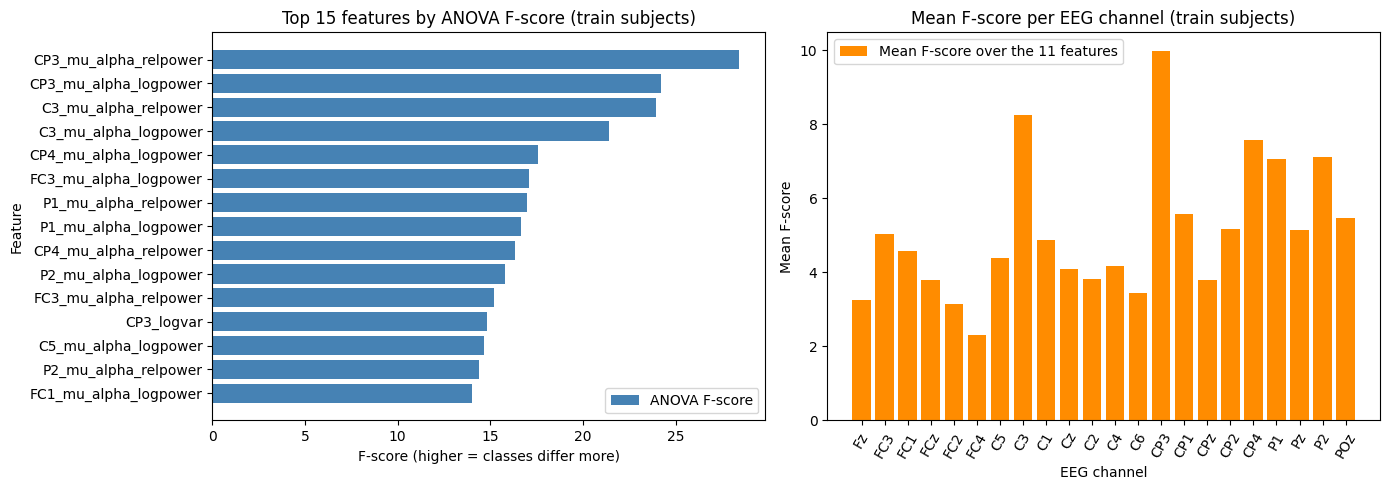

Reading: the most informative single feature is CP3_mu_alpha_relpower (F = 28.4). The five most informative channels are CP3, C3, CP4, P2, P1. Physiology predicts channels over the motor cortex (C3, C4, Cz and their neighbours), because hand, foot and tongue imagery change mu/beta power at different places on that strip. Check the list against that; if frontal channels (Fz, FC*) dominate instead, suspect leftover eye-movement activity.


In [10]:
F_scores, _ = f_classif(StandardScaler().fit_transform(X_train), y_train)
top = np.argsort(-F_scores)[:15]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh([TAB_NAMES[i] for i in top][::-1], F_scores[top][::-1], color="steelblue", label="ANOVA F-score")
axes[0].set(title="Top 15 features by ANOVA F-score (train subjects)", xlabel="F-score (higher = classes differ more)", ylabel="Feature")
axes[0].legend(loc="lower right")
ch_score = F_scores.reshape(N_CH, N_FEAT).mean(axis=1)
axes[1].bar(ch_names, ch_score, color="darkorange", label="Mean F-score over the 11 features")
axes[1].set(title="Mean F-score per EEG channel (train subjects)", xlabel="EEG channel", ylabel="Mean F-score")
axes[1].tick_params(axis="x", rotation=60); axes[1].legend()
finish(fig, "nb1_feature_scores.png")

best_ch = [ch_names[i] for i in np.argsort(-ch_score)[:5]]
print(f"Reading: the most informative single feature is {TAB_NAMES[top[0]]} (F = {F_scores[top[0]]:.1f}). "
      f"The five most informative channels are {', '.join(best_ch)}. "
      f"Physiology predicts channels over the motor cortex (C3, C4, Cz and their neighbours), because hand, foot and tongue imagery "
      f"change mu/beta power at different places on that strip. Check the list against that; if frontal channels (Fz, FC*) dominate instead, "
      f"suspect leftover eye-movement activity.")

## 6. Baseline models

Every model is wrapped in the same `Pipeline`:

`median imputation → StandardScaler → SelectKBest(ANOVA F) → classifier`

| Requirement | How it is handled |
|---|---|
| Missing values | `SimpleImputer(median)`; Task 1 found none, the step is a safety net |
| Scaling | `StandardScaler`, fitted on train subjects only |
| Encoding | features are all numeric; the class label is integer-encoded (section 3) |
| Imbalance | classes are balanced (72 per class per subject); `class_weight="balanced"` is still set where it exists |
| Feature selection | `SelectKBest`, k chosen on validation; Task 1 showed many features correlate above 0.9 |
| Leakage | the pipeline is fitted on train rows only, then applied to validation and test |

**Tuning protocol.** For each model a small grid is tried: fit on **train**, score **macro-F1 on the validation subject**. The best setting is refitted on train and evaluated on test once. Training time is the wall-clock time of that final fit.

In [11]:
def make_pipe(clf, k):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_classif, k=k)),
        ("clf", clf),
    ])

def get_proba(pipe, X):
    """Class scores for ROC / PR curves. SVM has no native probabilities, so its one-vs-rest
    decision values go through a softmax (Platt scaling via probability=True can contradict predict())."""
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)
    d = pipe.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

K_GRID = [60, 120, "all"]          # number of features kept by SelectKBest

MODEL_SPACE = {
    "Logistic Regression": (lambda **p: LogisticRegression(max_iter=3000, class_weight="balanced", **p),
                            {"C": [0.01, 0.1, 1.0]}),
    "SVM (RBF)":           (lambda **p: SVC(kernel="rbf", decision_function_shape="ovr", class_weight="balanced", random_state=SEED, **p),
                            {"C": [0.1, 1.0, 10.0]}),
    "k-NN":                (lambda **p: KNeighborsClassifier(weights="distance", **p),
                            {"n_neighbors": [5, 15, 31]}),
    "Decision Tree":       (lambda **p: DecisionTreeClassifier(class_weight="balanced", random_state=SEED, **p),
                            {"max_depth": [3, 5, 8]}),
    "Random Forest":       (lambda **p: RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED, **p),
                            {"max_depth": [6, None]}),
    "Gradient Boosting":   (lambda **p: GradientBoostingClassifier(n_estimators=200, subsample=0.8, max_features="sqrt", random_state=SEED, **p),
                            {"learning_rate": [0.05, 0.1], "max_depth": [2, 3]}),
    "MLP":                 (lambda **p: MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=500, random_state=SEED, **p),
                            {"alpha": [1e-3, 1e-1]}),
}
if HAS_XGB:
    MODEL_SPACE["XGBoost"] = (lambda **p: XGBClassifier(n_estimators=300, learning_rate=0.05, subsample=0.8, colsample_bytree=0.5,
                                                        tree_method="hist", n_jobs=-1, random_state=SEED, **p),
                              {"max_depth": [2, 4]})
if HAS_LGBM:
    MODEL_SPACE["LightGBM"] = (lambda **p: LGBMClassifier(n_estimators=300, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                                                          colsample_bytree=0.5, verbose=-1, n_jobs=-1, random_state=SEED, **p),
                               {"num_leaves": [7, 15]})
print("Baselines:", list(MODEL_SPACE))

Baselines: ['Logistic Regression', 'SVM (RBF)', 'k-NN', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'MLP', 'XGBoost', 'LightGBM']


In [12]:
results, fitted, best_cfg, tuning_rows = {}, {}, {}, []

for name, (factory, grid) in MODEL_SPACE.items():
    t_tune = time.time()
    best = (-1, None, None)
    for k in K_GRID:
        for params in ParameterGrid(grid):
            pipe = make_pipe(factory(**params), k).fit(X_train, y_train)
            f1v = f1_score(y_val, get_proba(pipe, X_val).argmax(1), average="macro")
            tuning_rows.append({"model": name, "k": k, **params, "val macro-F1": f1v})
            if f1v > best[0]:
                best = (f1v, k, params)
    f1v, k, params = best
    best_cfg[name] = (k, params)

    pipe = make_pipe(factory(**params), k)
    t0 = time.time(); pipe.fit(X_train, y_train); train_time = time.time() - t0     # final fit: TRAIN subjects only
    t0 = time.time(); proba = get_proba(pipe, X_test); infer_ms = 1000 * (time.time() - t0) / len(X_test)

    fitted[name] = pipe
    results[name] = {**compute_metrics(y_test, proba), "Val F1 (macro)": f1v, "Train time (s)": train_time,
                     "Inference (ms/trial)": infer_ms, "Best settings": f"k={k}, {params}", "proba": proba}
    print(f"{name:20s} val macro-F1 = {f1v:.3f} | test macro-F1 = {results[name]['F1 (macro)']:.3f} | "
          f"fit {train_time:6.2f}s | tuning {time.time() - t_tune:6.1f}s | k={k}, {params}")

tuning_df = pd.DataFrame(tuning_rows)

Logistic Regression  val macro-F1 = 0.265 | test macro-F1 = 0.232 | fit   0.12s | tuning   14.2s | k=60, {'C': 0.01}
SVM (RBF)            val macro-F1 = 0.260 | test macro-F1 = 0.139 | fit   0.63s | tuning    9.5s | k=all, {'C': 0.1}
k-NN                 val macro-F1 = 0.266 | test macro-F1 = 0.198 | fit   0.04s | tuning    0.7s | k=120, {'n_neighbors': 31}
Decision Tree        val macro-F1 = 0.318 | test macro-F1 = 0.272 | fit   0.44s | tuning    3.0s | k=all, {'max_depth': 5}
Random Forest        val macro-F1 = 0.256 | test macro-F1 = 0.175 | fit  13.63s | tuning   48.7s | k=all, {'max_depth': None}
Gradient Boosting    val macro-F1 = 0.273 | test macro-F1 = 0.247 | fit   5.18s | tuning   96.6s | k=60, {'learning_rate': 0.1, 'max_depth': 2}
MLP                  val macro-F1 = 0.249 | test macro-F1 = 0.196 | fit   1.14s | tuning    6.6s | k=all, {'alpha': 0.1}
XGBoost              val macro-F1 = 0.251 | test macro-F1 = 0.264 | fit   1.17s | tuning   45.0s | k=60, {'max_depth': 2}
Ligh

### 1D-CNN baseline (raw signal)
The other baselines use hand-made features. The 1D-CNN reads the filtered EEG directly (22 channels as input channels, down-sampled to 125 Hz) and learns its own temporal filters: three convolution blocks, global average pooling, one linear layer.

- Scaling: per-channel mean and standard deviation from the **train** subjects only
- Early stopping on the validation subject's loss; the test subjects are evaluated once at the end

Device: cpu
1D-CNN: stopped after 20 epochs (best = 5), 96.6s, test macro-F1 = 0.147


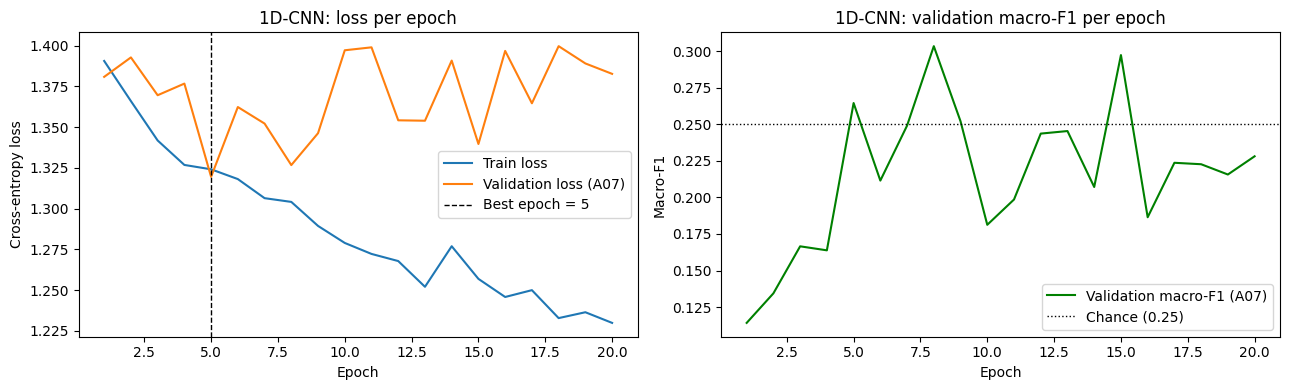

Reading: validation loss is lowest at epoch 5; the train/validation gap there is -0.00. Train and validation loss stay close, so the CNN is not strongly over-fitting the training subjects.


In [13]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

class CNN1D(nn.Module):
    def __init__(self, n_ch=22, n_cls=4, p=0.5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_ch, 32, 25, padding=12, bias=False), nn.BatchNorm1d(32), nn.ELU(), nn.AvgPool1d(4), nn.Dropout(p),
            nn.Conv1d(32, 64, 11, padding=5, bias=False),    nn.BatchNorm1d(64), nn.ELU(), nn.AvgPool1d(4), nn.Dropout(p),
            nn.Conv1d(64, 64, 5, padding=2, bias=False),     nn.BatchNorm1d(64), nn.ELU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(p), nn.Linear(64, n_cls),
        )
    def forward(self, x):
        return self.net(x)

Xc = Xf[:, :, ::2]                                              # 125 Hz (signal is already low-passed at 40 Hz)
mu_c = Xc[tr_idx].mean(axis=(0, 2), keepdims=True)              # train subjects only
sd_c = Xc[tr_idx].std(axis=(0, 2), keepdims=True) + 1e-6
Xc = ((Xc - mu_c) / sd_c).astype(np.float32)

def cnn_loader(idx, shuffle):
    ds = TensorDataset(torch.from_numpy(Xc[idx]), torch.from_numpy(y[idx]).long())
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

def cnn_pass(model, loader, crit, opt=None):
    model.train(opt is not None)
    tot, probs = 0.0, []
    with torch.set_grad_enabled(opt is not None):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb); loss = crit(out, yb)
            if opt is not None:
                opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(yb)
            probs.append(F.softmax(out, dim=1).detach().cpu().numpy())
    return tot / len(loader.dataset), np.concatenate(probs)

set_seed(SEED)
cnn = CNN1D().to(DEVICE)
opt = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-2)
crit = nn.CrossEntropyLoss()
dl_tr, dl_va, dl_te = cnn_loader(tr_idx, True), cnn_loader(va_idx, False), cnn_loader(te_idx, False)

MAX_EPOCHS, PATIENCE = 80, 15
cnn_hist = {"train_loss": [], "val_loss": [], "val_f1": []}
best_val, best_state, wait = np.inf, None, 0
t0 = time.time()
for ep in range(1, MAX_EPOCHS + 1):
    tl, _ = cnn_pass(cnn, dl_tr, crit, opt)
    vl, vp = cnn_pass(cnn, dl_va, crit)
    cnn_hist["train_loss"].append(tl); cnn_hist["val_loss"].append(vl)
    cnn_hist["val_f1"].append(f1_score(y_val, vp.argmax(1), average="macro"))
    if vl < best_val - 1e-4:
        best_val, best_state, wait = vl, copy.deepcopy(cnn.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            break
cnn_time = time.time() - t0
cnn.load_state_dict(best_state)
best_ep = int(np.argmin(cnn_hist["val_loss"])) + 1

_, vp = cnn_pass(cnn, dl_va, crit)
t0 = time.time(); _, proba_cnn = cnn_pass(cnn, dl_te, crit); cnn_inf = 1000 * (time.time() - t0) / len(te_idx)
n_par = sum(p.numel() for p in cnn.parameters())
results["1D-CNN"] = {**compute_metrics(y_test, proba_cnn), "Val F1 (macro)": f1_score(y_val, vp.argmax(1), average="macro"),
                     "Train time (s)": cnn_time, "Inference (ms/trial)": cnn_inf,
                     "Best settings": f"3 conv blocks, {n_par:,} params, AdamW lr=1e-3, dropout=0.5, best epoch={best_ep}", "proba": proba_cnn}
print(f"1D-CNN: stopped after {len(cnn_hist['val_loss'])} epochs (best = {best_ep}), {cnn_time:.1f}s, test macro-F1 = {results['1D-CNN']['F1 (macro)']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep_ax = np.arange(1, len(cnn_hist["val_loss"]) + 1)
axes[0].plot(ep_ax, cnn_hist["train_loss"], label="Train loss"); axes[0].plot(ep_ax, cnn_hist["val_loss"], label="Validation loss (A07)")
axes[0].axvline(best_ep, color="k", ls="--", lw=1, label=f"Best epoch = {best_ep}")
axes[0].set(title="1D-CNN: loss per epoch", xlabel="Epoch", ylabel="Cross-entropy loss"); axes[0].legend()
axes[1].plot(ep_ax, cnn_hist["val_f1"], color="green", label="Validation macro-F1 (A07)")
axes[1].axhline(0.25, color="k", ls=":", lw=1, label="Chance (0.25)")
axes[1].set(title="1D-CNN: validation macro-F1 per epoch", xlabel="Epoch", ylabel="Macro-F1"); axes[1].legend()
finish(fig, "nb1_cnn_training.png")
gap = cnn_hist["val_loss"][best_ep - 1] - cnn_hist["train_loss"][best_ep - 1]
print(f"Reading: validation loss is lowest at epoch {best_ep}; the train/validation gap there is {gap:.2f}. "
      f"{'Train loss keeps falling while validation loss rises afterwards, i.e. the CNN starts to fit the training subjects specifically; early stopping keeps the weights from before that.' if gap > 0.15 else 'Train and validation loss stay close, so the CNN is not strongly over-fitting the training subjects.'}")

## 7. Results on the held-out test subjects (A08, A09)

### 7.1 Comparison table
Sorted by macro-F1. With balanced classes, macro and weighted averages are almost the same; a gap between them would signal that one class is handled much worse than the others.

In [14]:
res_df = (pd.DataFrame({m: {k: v for k, v in r.items() if k != "proba"} for m, r in results.items()}).T
          .sort_values("F1 (macro)", ascending=False))
res_df.index.name = "Model"
num_cols = METRIC_COLS + ["Val F1 (macro)", "Train time (s)", "Inference (ms/trial)"]
res_df[num_cols] = res_df[num_cols].astype(float)
display(res_df[METRIC_COLS + ["Train time (s)", "Inference (ms/trial)"]].round(3))
display(res_df[["Val F1 (macro)", "Best settings"]].round(3))

BEST_BASELINE = res_df.index[0]
b = res_df.iloc[0]
print(f"\nBASELINE TO BEAT: {BEST_BASELINE}  ->  macro-F1 = {b['F1 (macro)']:.3f}, accuracy = {b['Accuracy']:.3f}, "
      f"macro ROC-AUC = {b['ROC-AUC (macro OvR)']:.3f}, training time = {b['Train time (s)']:.2f}s")
print(f"Reading: chance is 0.25. {(res_df['F1 (macro)'] > 0.30).sum()} of {len(res_df)} baselines are clearly above chance (macro-F1 > 0.30). "
      f"Best and worst differ by {res_df['F1 (macro)'].max() - res_df['F1 (macro)'].min():.3f} macro-F1. "
      f"The largest |macro-F1 - weighted-F1| gap is {(res_df['F1 (macro)'] - res_df['F1 (weighted)']).abs().max():.3f}, "
      f"as expected for balanced classes.")

,Accuracy,Balanced acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AUC (macro OvR),Train time (s),Inference (ms/trial)
Model,,,,,,,,,,,,
Decision Tree,0.333,0.333,0.329,0.333,0.272,0.329,0.333,0.272,0.548,0.291,0.445,0.006
XGBoost,0.333,0.333,0.516,0.333,0.264,0.516,0.333,0.264,0.643,0.380,1.175,0.020
LightGBM,0.328,0.328,0.423,0.328,0.257,0.423,0.328,0.257,0.626,0.370,1.090,0.046
Gradient Boosting,0.293,0.293,0.330,0.293,0.247,0.330,0.293,0.247,0.588,0.315,5.176,0.025
Logistic Regression,0.312,0.312,0.457,0.312,0.232,0.457,0.312,0.232,0.682,0.420,0.125,0.008
k-NN,0.293,0.293,0.337,0.293,0.198,0.337,0.293,0.198,0.601,0.335,0.043,0.043
MLP,0.292,0.292,0.452,0.292,0.196,0.452,0.292,0.196,0.685,0.432,1.140,0.015
Random Forest,0.278,0.278,0.315,0.278,0.175,0.315,0.278,0.175,0.580,0.308,13.630,0.356
1D-CNN,0.274,0.274,0.124,0.274,0.147,0.124,0.274,0.147,0.674,0.419,96.625,1.000


,Val F1 (macro),Best settings
Model,,
Decision Tree,0.318,"k=all, {'max_depth': 5}"
XGBoost,0.251,"k=60, {'max_depth': 2}"
LightGBM,0.267,"k=60, {'num_leaves': 7}"
Gradient Boosting,0.273,"k=60, {'learning_rate': 0.1, 'max_depth': 2}"
Logistic Regression,0.265,"k=60, {'C': 0.01}"
k-NN,0.266,"k=120, {'n_neighbors': 31}"
MLP,0.249,"k=all, {'alpha': 0.1}"
Random Forest,0.256,"k=all, {'max_depth': None}"
1D-CNN,0.264,"3 conv blocks, 61,188 params, AdamW lr=1e-3, d..."



BASELINE TO BEAT: Decision Tree  ->  macro-F1 = 0.272, accuracy = 0.333, macro ROC-AUC = 0.548, training time = 0.44s
Reading: chance is 0.25. 0 of 10 baselines are clearly above chance (macro-F1 > 0.30). Best and worst differ by 0.133 macro-F1. The largest |macro-F1 - weighted-F1| gap is 0.000, as expected for balanced classes.


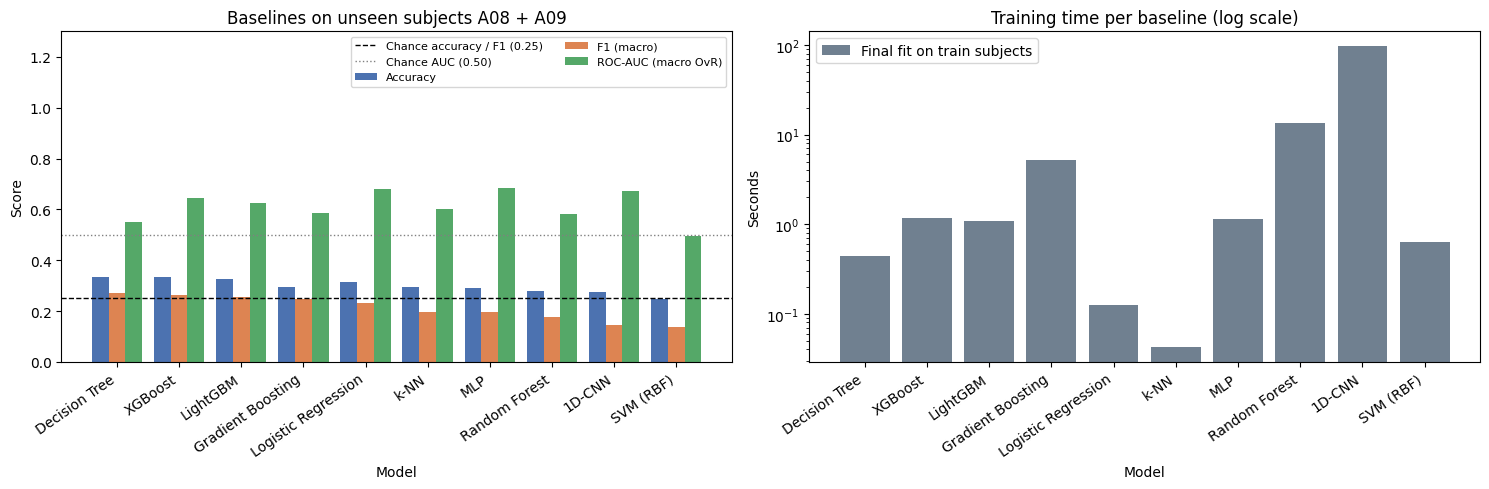

Reading: Decision Tree has the highest macro-F1. Fastest to train = k-NN (0.04s), slowest = 1D-CNN (96.6s). The best model costs 0.44s, so check whether a much cheaper model is within ~0.02 macro-F1 of it.


In [15]:
order = res_df.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(order)); w = 0.27
for i, (col, colr) in enumerate([("Accuracy", "#4C72B0"), ("F1 (macro)", "#DD8452"), ("ROC-AUC (macro OvR)", "#55A868")]):
    axes[0].bar(x + (i - 1) * w, res_df[col], w, label=col, color=colr)
axes[0].axhline(0.25, color="k", ls="--", lw=1, label="Chance accuracy / F1 (0.25)")
axes[0].axhline(0.50, color="gray", ls=":", lw=1, label="Chance AUC (0.50)")
axes[0].set_xticks(x); axes[0].set_xticklabels(order, rotation=35, ha="right")
axes[0].set(title="Baselines on unseen subjects A08 + A09", xlabel="Model", ylabel="Score", ylim=(0, 1.3)); axes[0].legend(fontsize=8, ncol=2, loc="upper right")
axes[1].bar(order, res_df["Train time (s)"], color="slategray", label="Final fit on train subjects")
axes[1].set_yscale("log"); axes[1].tick_params(axis="x", rotation=35)
plt.setp(axes[1].get_xticklabels(), ha="right")
axes[1].set(title="Training time per baseline (log scale)", xlabel="Model", ylabel="Seconds"); axes[1].legend()
finish(fig, "nb1_baseline_comparison.png")

fastest, slowest = res_df["Train time (s)"].idxmin(), res_df["Train time (s)"].idxmax()
print(f"Reading: {BEST_BASELINE} has the highest macro-F1. Fastest to train = {fastest} ({res_df.loc[fastest, 'Train time (s)']:.2f}s), "
      f"slowest = {slowest} ({res_df.loc[slowest, 'Train time (s)']:.1f}s). "
      f"The best model costs {res_df.loc[BEST_BASELINE, 'Train time (s)']:.2f}s, so check whether a much cheaper model is within ~0.02 macro-F1 of it.")

### 7.2 Per-class recall for every model
Overall accuracy can hide a class the model never predicts; per-class recall shows it.

In [16]:
recall_df = pd.DataFrame({m: recall_score(y_test, results[m]["proba"].argmax(1), average=None, labels=np.arange(N_CLASSES))
                          for m in order}, index=CLASS_NAMES).T
recall_df.index.name = "Model"
display(recall_df.round(3))
print(f"Reading: averaged over models, the easiest class is {recall_df.mean().idxmax()} (mean recall {recall_df.mean().max():.2f}) "
      f"and the hardest is {recall_df.mean().idxmin()} (mean recall {recall_df.mean().min():.2f}). "
      f"Lowest single value: {recall_df.stack().idxmin()[0]} on {recall_df.stack().idxmin()[1]} = {recall_df.stack().min():.2f}.")

,Left hand,Right hand,Both feet,Tongue
Model,,,,
Decision Tree,0.243,0.125,0.083,0.882
XGBoost,0.028,0.215,0.208,0.882
LightGBM,0.028,0.243,0.153,0.889
Gradient Boosting,0.035,0.181,0.278,0.681
Logistic Regression,0.021,0.160,0.153,0.917
k-NN,0.014,0.097,0.125,0.938
MLP,0.083,0.076,0.049,0.958
Random Forest,0.021,0.021,0.153,0.917
1D-CNN,0.000,0.000,0.111,0.986


Reading: averaged over models, the easiest class is Tongue (mean recall 0.89) and the hardest is Left hand (mean recall 0.05). Lowest single value: 1D-CNN on Left hand = 0.00.


### 7.3 Confusion matrices (row-normalised; counts in brackets)

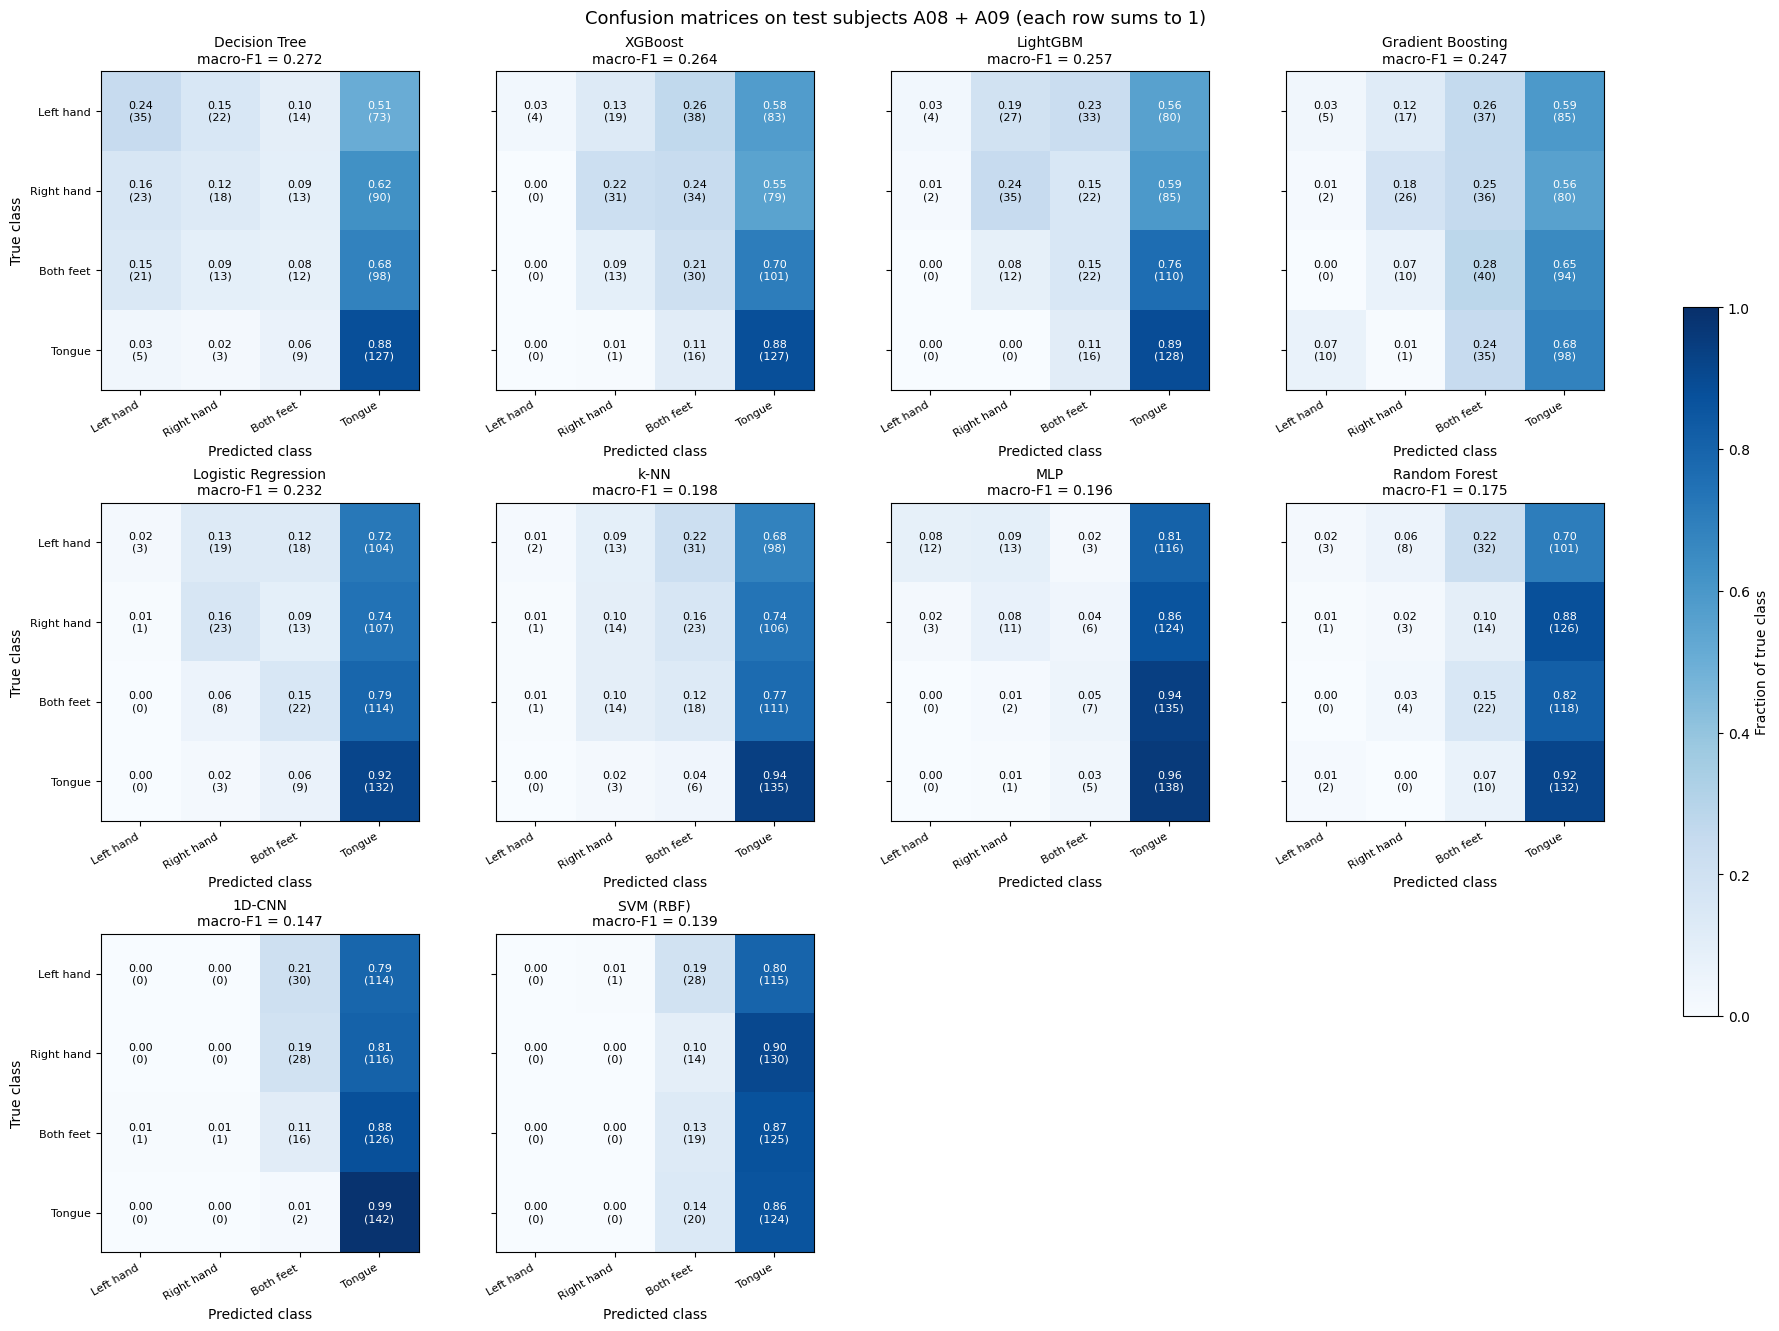

Reading (Decision Tree): best-recognised class = Tongue (recall 0.88); weakest = Both feet (recall 0.08); most common mistake = true 'Both feet' predicted as 'Tongue' (68% of those trials).
Reading (XGBoost): best-recognised class = Tongue (recall 0.88); weakest = Left hand (recall 0.03); most common mistake = true 'Both feet' predicted as 'Tongue' (70% of those trials).
Reading (LightGBM): best-recognised class = Tongue (recall 0.89); weakest = Left hand (recall 0.03); most common mistake = true 'Both feet' predicted as 'Tongue' (76% of those trials).
Note: left vs right hand are produced by mirror-image areas of the motor cortex, so confusing them across people is expected; feet (central, near Cz) and tongue usually separate from the hands more easily.


In [17]:
n = len(order); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 4.4 * nrow), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()
for j, (ax, m) in enumerate(zip(axes, order)):
    im = plot_confusion(ax, y_test, results[m]["proba"].argmax(1), f"{m}\nmacro-F1 = {results[m]['F1 (macro)']:.3f}", ylabel=(j % ncol == 0))
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle("Confusion matrices on test subjects A08 + A09 (each row sums to 1)", fontsize=13)
fig.colorbar(im, ax=axes.tolist(), shrink=0.6, label="Fraction of true class")
fig.savefig(os.path.join(FIG_DIR, "nb1_confusion_matrices.png"), dpi=150, bbox_inches="tight"); plt.show()
for m in order[:3]:
    read_confusion(y_test, results[m]["proba"].argmax(1), m)
print("Note: left vs right hand are produced by mirror-image areas of the motor cortex, so confusing them across people is expected; "
      "feet (central, near Cz) and tongue usually separate from the hands more easily.")

### 7.4 Best baseline in detail: per-class report, ROC and precision–recall curves (one-vs-rest)

Per-class report for the best baseline: Decision Tree


,precision,recall,f1-score,ROC-AUC,support
class,,,,,
Left hand,0.417,0.243,0.307,0.556,144
Right hand,0.321,0.125,0.180,0.538,144
Both feet,0.250,0.083,0.125,0.487,144
Tongue,0.327,0.882,0.477,0.613,144
macro avg,0.329,0.333,0.272,0.548,576
weighted avg,0.329,0.333,0.272,0.548,576


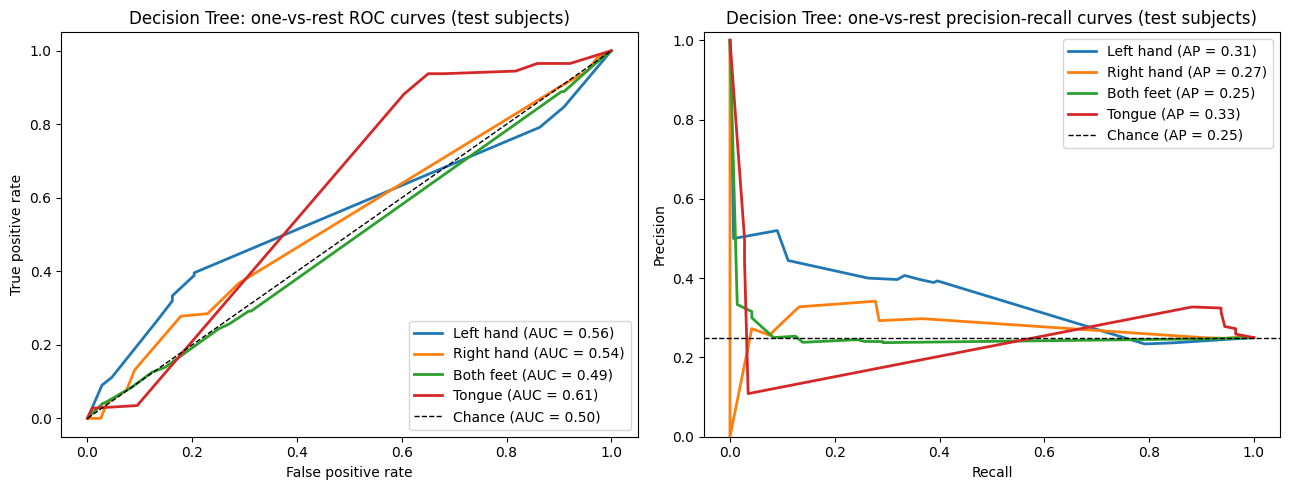

Reading (Decision Tree): every curve above the dashed line means the model ranks that class better than chance. Easiest class to separate = Tongue (AUC 0.61, AP 0.33); hardest = Both feet (AUC 0.49, AP 0.25). Macro AUC = 0.548; chance is 0.50 for AUC and 0.25 for AP.


In [18]:
print("Per-class report for the best baseline:", BEST_BASELINE)
display(per_class_table(y_test, results[BEST_BASELINE]["proba"]).round(3))
plot_ovr_curves(y_test, results[BEST_BASELINE]["proba"], BEST_BASELINE, "nb1_best_baseline_roc_pr.png")

### 7.5 All baselines on one ROC and one PR plot (micro-average over the four one-vs-rest problems)

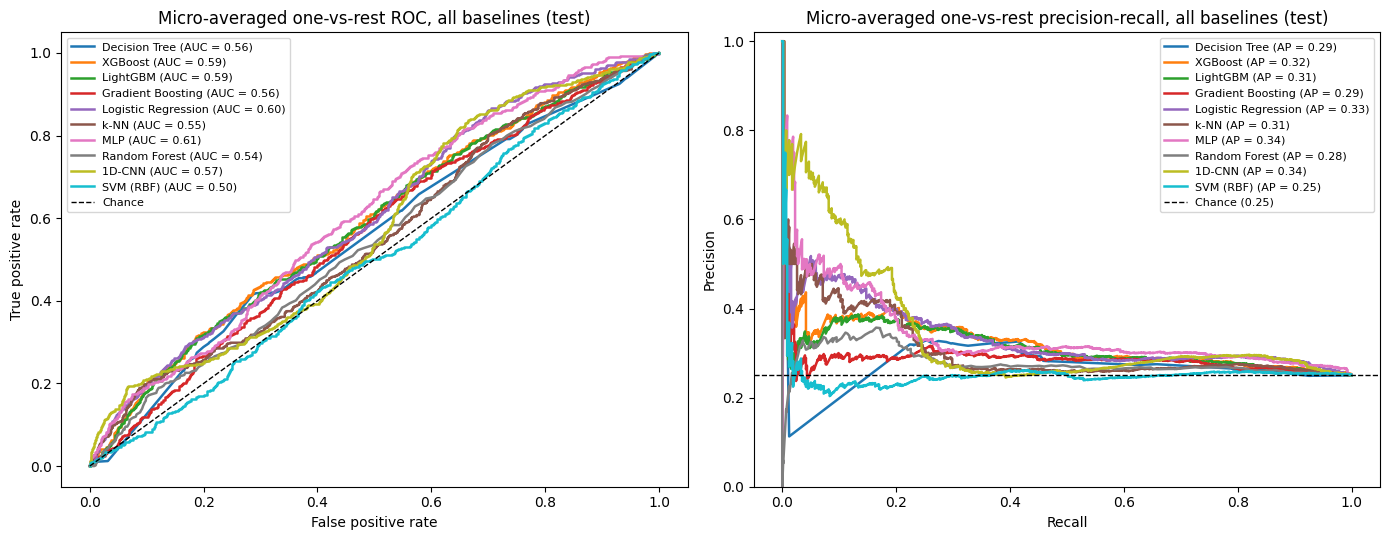

Reading: curves further from the dashed line are better. Ranking by macro ROC-AUC: MLP, Logistic Regression, 1D-CNN lead. If the AUC ranking differs from the macro-F1 ranking, that model orders trials well but its decision threshold is off.


In [19]:
Yb = label_binarize(y_test, classes=np.arange(N_CLASSES))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for m in order:
    p = results[m]["proba"]
    fpr, tpr, _ = roc_curve(Yb.ravel(), p.ravel()); axes[0].plot(fpr, tpr, lw=1.8, label=f"{m} (AUC = {auc(fpr, tpr):.2f})")
    pr, rc, _ = precision_recall_curve(Yb.ravel(), p.ravel()); axes[1].plot(rc, pr, lw=1.8, label=f"{m} (AP = {average_precision_score(Yb.ravel(), p.ravel()):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
axes[0].set(title="Micro-averaged one-vs-rest ROC, all baselines (test)", xlabel="False positive rate", ylabel="True positive rate"); axes[0].legend(fontsize=8)
axes[1].axhline(0.25, color="k", ls="--", lw=1, label="Chance (0.25)")
axes[1].set(title="Micro-averaged one-vs-rest precision-recall, all baselines (test)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02)); axes[1].legend(fontsize=8)
finish(fig, "nb1_all_models_roc_pr.png")
print(f"Reading: curves further from the dashed line are better. Ranking by macro ROC-AUC: "
      f"{', '.join(res_df['ROC-AUC (macro OvR)'].sort_values(ascending=False).index[:3])} lead. "
      f"If the AUC ranking differs from the macro-F1 ranking, that model orders trials well but its decision threshold is off.")

### 7.6 Does the result depend on the test person?
Each test subject separately. Large differences are normal in BCI data: some people produce much clearer motor-imagery patterns than others.

In [20]:
rows = []
for m in order:
    pred = results[m]["proba"].argmax(1)
    row = {"Model": m}
    for s in TEST_SUBJECTS:
        mask = subjects[te_idx] == s
        row[f"{s} accuracy"] = accuracy_score(y_test[mask], pred[mask])
        row[f"{s} macro-F1"] = f1_score(y_test[mask], pred[mask], average="macro")
    rows.append(row)
per_subj_df = pd.DataFrame(rows).set_index("Model")
display(per_subj_df.round(3))
f1c = [c for c in per_subj_df.columns if "macro-F1" in c]
print(f"Reading: for {BEST_BASELINE}, macro-F1 is " + ", ".join(f"{per_subj_df.loc[BEST_BASELINE, c]:.3f} on {c[:3]}" for c in f1c) +
      f". Mean over models: " + ", ".join(f"{c[:3]} = {per_subj_df[c].mean():.3f}" for c in f1c) + ".")

,A08 accuracy,A08 macro-F1,A09 accuracy,A09 macro-F1
Model,,,,
Decision Tree,0.344,0.291,0.323,0.250
XGBoost,0.365,0.310,0.302,0.209
LightGBM,0.375,0.320,0.281,0.176
Gradient Boosting,0.312,0.268,0.274,0.224
Logistic Regression,0.312,0.224,0.312,0.239
k-NN,0.312,0.226,0.274,0.166
MLP,0.278,0.175,0.306,0.213
Random Forest,0.292,0.190,0.264,0.155
1D-CNN,0.288,0.167,0.260,0.123


Reading: for Decision Tree, macro-F1 is 0.291 on A08, 0.250 on A09. Mean over models: A08 = 0.232, A09 = 0.188.


## 8. Leave-one-subject-out (LOSO) check
Two test subjects is a small sample of people. LOSO repeats the experiment nine times, each time testing on one person and training on the other eight, with the pipeline refitted from scratch every time.

Caveat: the settings chosen in section 6 are reused, and those were picked with A07 as validation, so this is a robustness check rather than a second fully independent test. The 1D-CNN is left out to keep the run time short.

LOSO done: Logistic Regression
LOSO done: SVM (RBF)
LOSO done: k-NN
LOSO done: Decision Tree
LOSO done: Random Forest
LOSO done: Gradient Boosting
LOSO done: MLP
LOSO done: XGBoost
LOSO done: LightGBM


Accuracy        F1 (macro)       
                        mean    std       mean    std
Model                                                
Logistic Regression    0.327  0.063      0.276  0.092
LightGBM               0.278  0.042      0.238  0.049
Gradient Boosting      0.279  0.039      0.236  0.039
k-NN                   0.270  0.024      0.234  0.046
MLP                    0.289  0.034      0.230  0.061
XGBoost                0.274  0.046      0.229  0.040
Random Forest          0.268  0.029      0.227  0.043
Decision Tree          0.265  0.028      0.205  0.052
SVM (RBF)              0.269  0.018      0.165  0.046

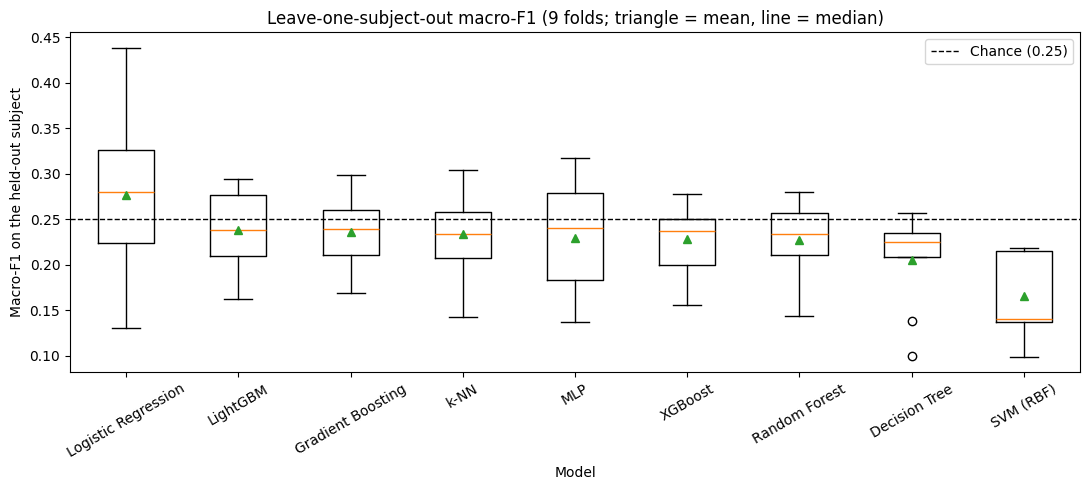

Reading: best LOSO model = Logistic Regression (macro-F1 0.276 +/- 0.092). The fixed split preferred Decision Tree; the two disagree, so the gap between the top models is within subject-to-subject noise. Easiest person to predict = A01 (0.274), hardest = A09 (0.173). Spread across people (std of subject means) = 0.035; spread across models (std of model means) = 0.030. Whichever is larger is the main source of variation in these scores.


In [21]:
all_subjects = sorted(set(subjects))
loso_rows = []
for name, (factory, _) in MODEL_SPACE.items():
    k, params = best_cfg[name]
    for s in all_subjects:
        tr, te = subjects != s, subjects == s
        pipe = make_pipe(factory(**params), k).fit(X_tab[tr], y[tr])
        pred = get_proba(pipe, X_tab[te]).argmax(1)
        loso_rows.append({"Model": name, "Test subject": s, "Accuracy": accuracy_score(y[te], pred),
                          "F1 (macro)": f1_score(y[te], pred, average="macro")})
    print("LOSO done:", name)
loso_df = pd.DataFrame(loso_rows)

loso_summary = loso_df.groupby("Model")[["Accuracy", "F1 (macro)"]].agg(["mean", "std"]).sort_values(("F1 (macro)", "mean"), ascending=False)
display(loso_summary.round(3))

lo_order = loso_summary.index.tolist()
fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([loso_df.loc[loso_df.Model == m, "F1 (macro)"] for m in lo_order], showmeans=True)
ax.set_xticks(range(1, len(lo_order) + 1)); ax.set_xticklabels(lo_order)
ax.axhline(0.25, color="k", ls="--", lw=1, label="Chance (0.25)")
ax.set(title="Leave-one-subject-out macro-F1 (9 folds; triangle = mean, line = median)", xlabel="Model", ylabel="Macro-F1 on the held-out subject")
ax.tick_params(axis="x", rotation=30); ax.legend()
finish(fig, "nb1_loso.png")

by_subj = loso_df.groupby("Test subject")["F1 (macro)"].mean()
top_loso = lo_order[0]
print(f"Reading: best LOSO model = {top_loso} (macro-F1 {loso_summary.loc[top_loso, ('F1 (macro)', 'mean')]:.3f} "
      f"+/- {loso_summary.loc[top_loso, ('F1 (macro)', 'std')]:.3f}). "
      f"{'This agrees with the fixed split.' if top_loso == BEST_BASELINE else f'The fixed split preferred {BEST_BASELINE}; the two disagree, so the gap between the top models is within subject-to-subject noise.'} "
      f"Easiest person to predict = {by_subj.idxmax()} ({by_subj.max():.3f}), hardest = {by_subj.idxmin()} ({by_subj.min():.3f}). "
      f"Spread across people (std of subject means) = {by_subj.std():.3f}; spread across models (std of model means) = "
      f"{loso_summary[('F1 (macro)', 'mean')].std():.3f}. Whichever is larger is the main source of variation in these scores.")

## 9. Save results for Notebook 2

In [22]:
res_df.to_csv(os.path.join(RESULTS_DIR, "baseline_results.csv"))
recall_df.to_csv(os.path.join(RESULTS_DIR, "baseline_per_class_recall.csv"))
tuning_df.to_csv(os.path.join(RESULTS_DIR, "baseline_tuning_log.csv"), index=False)
loso_df.to_csv(os.path.join(RESULTS_DIR, "baseline_loso.csv"), index=False)
json.dump({"train_subjects": TRAIN_SUBJECTS, "val_subjects": VAL_SUBJECTS, "test_subjects": TEST_SUBJECTS,
           "best_baseline": BEST_BASELINE, "best_baseline_macro_f1": float(res_df.loc[BEST_BASELINE, "F1 (macro)"])},
          open(os.path.join(RESULTS_DIR, "baseline_summary.json"), "w"), indent=2)
print("Saved to", RESULTS_DIR)
print(f"Baseline to beat in Notebook 2: {BEST_BASELINE} (macro-F1 = {res_df.loc[BEST_BASELINE, 'F1 (macro)']:.3f})")

Saved to /content/drive/MyDrive/475_mini_proj/Task2_Results
Baseline to beat in Notebook 2: Decision Tree (macro-F1 = 0.272)


## 10. Summary (fill in the numbers after running)

- **Protocol.** Subject-independent split (train A01–A06, validation A07, test A08–A09); all preprocessing inside a pipeline fitted on train subjects only; EOG channels removed.
- **Baseline to beat.** The model named in the output of section 7.1, with its macro-F1, accuracy, macro ROC-AUC and training time. Copy those four numbers here.
- **Where the baselines fail.** Use the readings under 7.2 and 7.3: which class has the lowest recall and which pair is confused most.
- **How stable it is.** Use 7.6 and section 8: the difference between people and the LOSO mean ± standard deviation.
- **Why a GNN next.** Every baseline here treats the 242 features as an unordered list. None of them knows which features come from the same electrode, or which electrodes behave alike. Notebook 2 gives the model that structure as a graph.